In [7]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn)
import warnings
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42   

In [8]:
data = pd.read_csv('/Users/elyne/Desktop/AI Journey/ITS/ML/FP-MachineLearning/Dataset/Paddy/paddydataset.csv')
data

      Hectares      Agriblock      Variety Soil Types  Seedrate(in Kg)  \
0             6     Cuddalore        CO_43   alluvial              150   
1             6   Kurinjipadi      ponmani       clay              150   
2             6       Panruti  delux ponni   alluvial              150   
3             6  Kallakurichi        CO_43       clay              150   
4             6  Sankarapuram      ponmani   alluvial              150   
...         ...           ...          ...        ...              ...   
2784          1  Kallakurichi        CO_43   alluvial               25   
2785          1  Sankarapuram      ponmani       clay               25   
2786          1   Chinnasalem  delux ponni       clay               25   
2787          1     Cuddalore        CO_43   alluvial               25   
2788          1   Kurinjipadi  delux ponni       clay               25   

      LP_Mainfield(in Tonnes) Nursery  Nursery area (Cents)  \
0                        75.0     dry           

## EDA 

In [9]:
print(data.shape)
data.info()

(2789, 45)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Hectares                            2789 non-null   int64  
 1   Agriblock                           2789 non-null   object 
 2   Variety                             2789 non-null   object 
 3   Soil Types                          2789 non-null   object 
 4   Seedrate(in Kg)                     2789 non-null   int64  
 5   LP_Mainfield(in Tonnes)             2789 non-null   float64
 6   Nursery                             2789 non-null   object 
 7   Nursery area (Cents)                2789 non-null   int64  
 8   LP_nurseryarea(in Tonnes)           2789 non-null   int64  
 9   DAP_20days                          2789 non-null   int64  
 10  Weed28D_thiobencarb                 2789 non-null   int64  
 11  Urea_40Days                     

In [10]:
print('Missing value :', data.isna().sum().sum())
print('Duplikat      :', data.duplicated().sum())

Missing value : 0
Duplikat      : 451


In [11]:
data.describe().T

                                     count          mean          std  \
Hectares                            2789.0      3.717461     1.437777   
Seedrate(in Kg)                     2789.0     92.936536    35.944420   
LP_Mainfield(in Tonnes)             2789.0     46.468268    17.972210   
Nursery area (Cents)                2789.0     74.349229    28.755536   
LP_nurseryarea(in Tonnes)           2789.0      3.717461     1.437777   
DAP_20days                          2789.0    148.698458    57.511072   
Weed28D_thiobencarb                 2789.0      7.434923     2.875554   
Urea_40Days                         2789.0    100.854729    39.006885   
Potassh_50Days                      2789.0     38.587250    14.924123   
Micronutrients_70Days               2789.0     55.761922    21.566652   
Pest_60Day(in ml)                   2789.0   2230.476873   862.666087   
30DRain( in mm)                     2789.0     18.723593     0.643789   
30DAI(in mm)                        2789.0     21.2

In [12]:
data.describe(include='object').T

                        count unique           top  freq
Agriblock                2789      6  Sankarapuram   605
Variety                  2789      3       ponmani  1061
Soil Types               2789      2          clay  1521
Nursery                  2789      2           dry  1540
Wind Direction_D1_D30    2789      6           SSE   605
Wind Direction_D31_D60   2789      5             W  1055
Wind Direction_D61_D90   2789      5            SE   899
Wind Direction_D91_D120  2789      6            NW   605

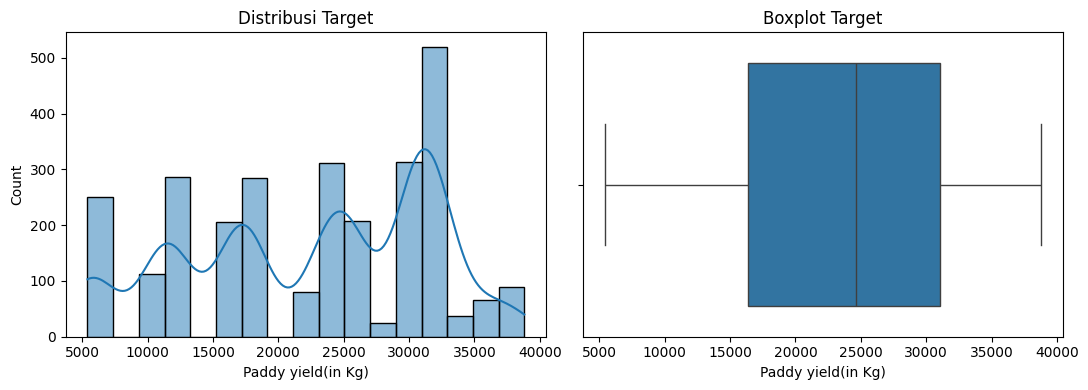

In [13]:
target = 'Paddy yield(in Kg)'
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data[target], kde=True, ax=ax[0])
sns.boxplot(x=data[target], ax=ax[1])
ax[0].set_title('Distribusi Target'); ax[1].set_title('Boxplot Target')
plt.tight_layout(); plt.show()

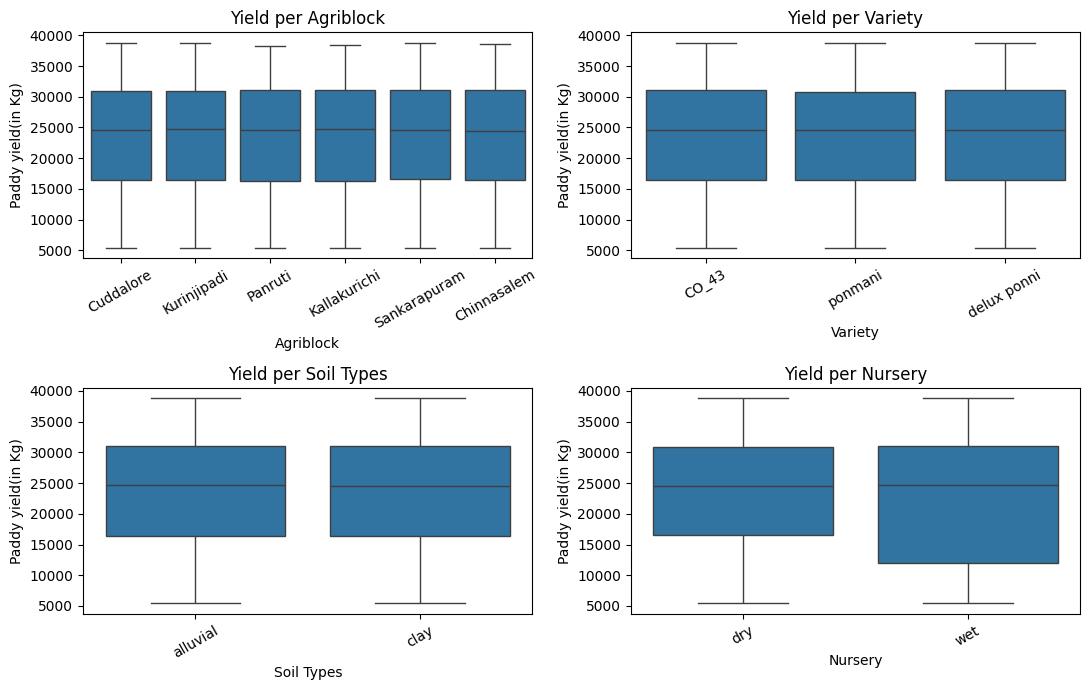

In [14]:
cat_cols = ['Agriblock', 'Variety', 'Soil Types', 'Nursery']
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, c in zip(ax.ravel(), cat_cols):
    sns.boxplot(data=data, x=c, y=target, ax=a)
    a.set_title(f'Yield per {c}'); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

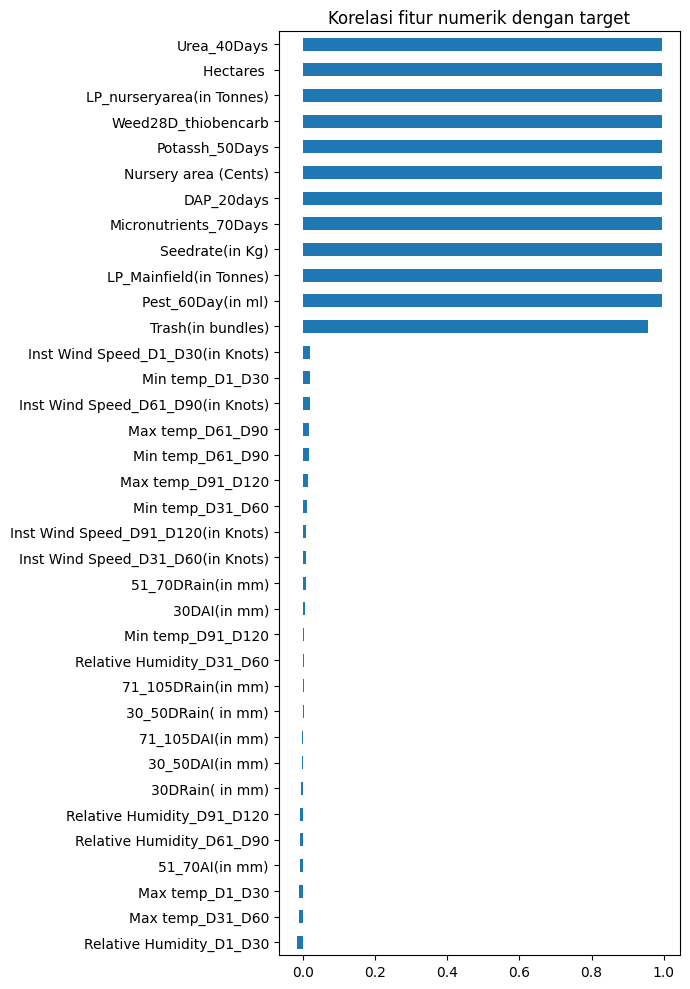

In [15]:
corr = data.select_dtypes('number').corr()[target].drop(target).sort_values()
plt.figure(figsize=(7, 10))
corr.plot.barh()
plt.title('Korelasi fitur numerik dengan target')
plt.tight_layout(); plt.show()

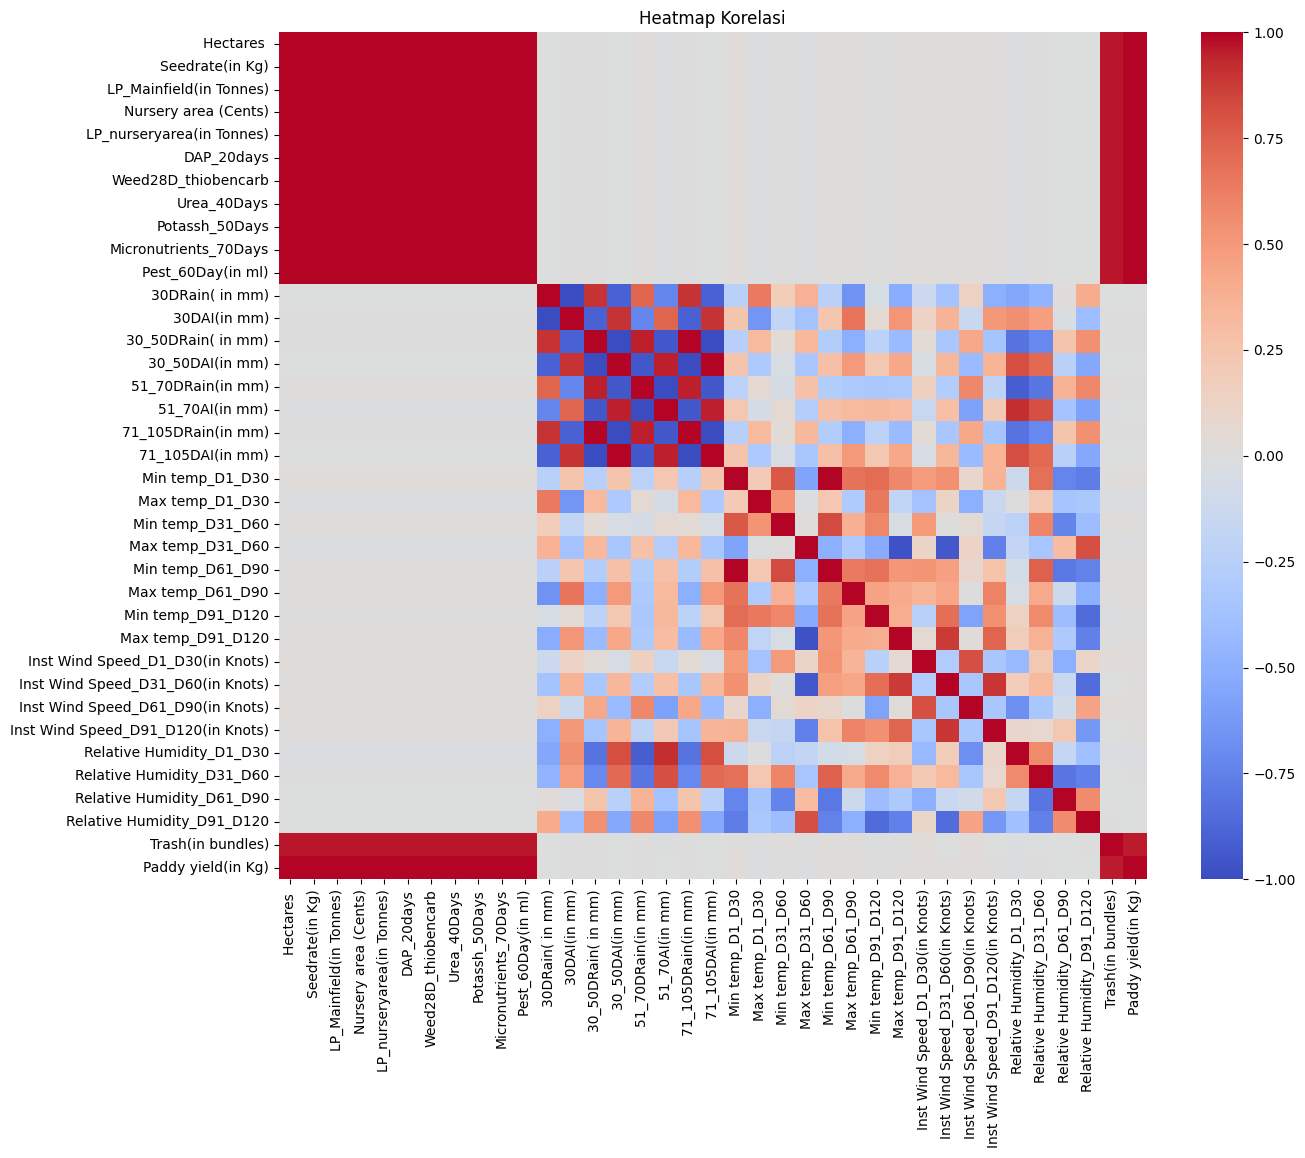

In [16]:
num = data.select_dtypes('number')
plt.figure(figsize=(14, 11))
sns.heatmap(num.corr(), cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi'); plt.show()